# Implementación técnica — Modelo predictivo de costos médicos
### Evaluación Parcial N°3 · SCY1102 Gestión de Proyectos de Datos · Duoc UC

Integrantes: Moira Bittner, Nicolás Carrasco, Martín Corvalán, Martín Naranjo · Docente: Anibal Sotelo

---

Este notebook es el respaldo técnico del informe. Aquí está todo lo que implementamos en las fases de
**Preparación, Modelado y Evaluación** de CRISP-DM, y cada sección está amarrada a una tarjeta del
tablero de Trello, para que se pueda seguir el hilo entre el plan y lo que realmente hicimos.

| Sección | Tarea en Trello | Hito |
|---|---|---|
| 1. Calidad de los datos | T3 – Explorar el dataset | H2 |
| 2. Preparación | T4 – Limpieza, variables nuevas y exclusión de sexo | H3 |
| 3. Entrenamiento y comparación | T5 – Entrenar modelos | H4 |
| 4. Validación cruzada | T6 – Validación cruzada y criterio RF1 | H4 |
| 5. Auditoría de equidad | T7 – Auditoría de equidad por subgrupo | H5 |
| 6. Acción correctiva | T14 – Probar modelo sin región y con log del costo *(no planificada)* | H5 |
| 7. Puerta de calidad | T11 – Automatización del reentrenamiento | H6 |
| 8. Salida para el dashboard | T10 / T13 – Dashboard y decil de mayor costo | H6 |
| 9. Respaldo del monitoreo | Gantt plan vs. real (sección 1.2 del informe) | — |

**Cómo ejecutarlo:** dejar `insurance.csv` en la carpeta `data/` del repositorio y ejecutar todas las celdas
en orden (*Run All*). Las figuras quedan en la carpeta `figuras/` y la salida para el dashboard en
`salidas/`. Usamos `random_state=42` en todo, así que los resultados siempre son los mismos.

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, cross_validate, cross_val_predict
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import r2_score, mean_absolute_error
warnings.filterwarnings("ignore")

SEMILLA = 42
os.makedirs("figuras", exist_ok=True)
os.makedirs("salidas", exist_ok=True)

# Misma paleta que usamos en el informe de factibilidad (EP1)
AZUL, NARANJA, AQUA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#b5b4b0"
TINTA, TINTA2, FONDO = "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "axes.edgecolor": "#d6d5d1", "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 9.5,
    "axes.titleweight": "bold", "axes.titlecolor": TINTA, "figure.dpi": 110,
})

df_original = pd.read_csv("../data/insurance.csv")
df_original.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## 1. Calidad de los datos (T3 · H2 · RD1)

Antes de modelar revisamos lo mismo que comprometimos en el requerimiento de datos RD1: nulos, duplicados,
rango de edad y origen.

In [2]:
print(f"Registros: {df_original.shape[0]} | Variables: {df_original.shape[1]}")
print(f"Valores nulos: {df_original.isna().sum().sum()}")
print(f"Registros duplicados: {df_original.duplicated().sum()}")
print(f"Rango de edad: {df_original.age.min()} a {df_original.age.max()} años (mayores de 65: {(df_original.age > 65).sum()})")
print(f"Regiones: {sorted(df_original.region.unique())}")
print(f"Fumadores: {(df_original.smoker == 'yes').mean():.1%} | IMC ≥ 30: {(df_original.bmi >= 30).mean():.1%}")

Registros: 1338 | Variables: 7
Valores nulos: 0
Registros duplicados: 1
Rango de edad: 18 a 64 años (mayores de 65: 0)
Regiones: ['northeast', 'northwest', 'southeast', 'southwest']
Fumadores: 20.5% | IMC ≥ 30: 52.8%


**Conclusión.** Los datos están completos y sólo tienen un duplicado. Las limitaciones que ya conocíamos siguen
ahí (no hay mayores de 65 años y los datos son de EE. UU.), por eso el modelo es un prototipo y no se usa en una
cartera chilena sin el dataset local que exige la condición de salida del informe de factibilidad.

## 2. Preparación de los datos (T4 · H3)

Tres decisiones, todas tomadas en el plan del proyecto:

1. **Eliminar el registro duplicado** (RD1).
2. **Excluir la variable sexo como predictor** (RF1 y restricción RR1, doctrina de la tabla única de factores).
   El sexo se mantiene en la tabla sólo para auditar el error por subgrupo (RF2).
3. **Crear variables nuevas** que capturan lo que encontramos en la exploración: el gasto se dispara
   cuando se combinan tabaquismo y obesidad, así que agregamos `obeso` (IMC ≥ 30) y la interacción `fumador × obeso`.

In [3]:
df = df_original.drop_duplicates().reset_index(drop=True)
df["fumador"] = (df.smoker == "yes").astype(int)
df["obeso"] = (df.bmi >= 30).astype(int)
df["fumador_x_obeso"] = df.fumador * df.obeso
df["tramo_edad"] = pd.cut(df.age, [17, 34, 49, 64], labels=["18–34", "35–49", "50–64"])
df["tramo_imc"] = np.where(df.bmi >= 30, "IMC ≥ 30", "IMC < 30")

def construir_X(datos, con_region=True):
    # Matriz de predictores. El sexo nunca entra.
    X = datos[["age", "bmi", "children", "fumador", "obeso", "fumador_x_obeso"]].copy()
    if con_region:
        X = X.join(pd.get_dummies(datos.region, prefix="region", drop_first=True).astype(int))
    return X

X = construir_X(df)
y = df.charges
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=SEMILLA)
print(f"Registros después de limpiar: {len(df)}")
print(f"Entrenamiento: {len(X_tr)} | Prueba: {len(X_te)}")
print("Predictores:", list(X.columns))

Registros después de limpiar: 1337
Entrenamiento: 1002 | Prueba: 335
Predictores: ['age', 'bmi', 'children', 'fumador', 'obeso', 'fumador_x_obeso', 'region_northwest', 'region_southeast', 'region_southwest']


## 3. Entrenamiento y comparación de modelos (T5 · H4)

Comparamos tres modelos contra una **línea base** que predice siempre el promedio. El criterio de aceptación
de **RF1** es: R² ≥ 0,80 y MAE al menos 60 % menor que la línea base.

In [4]:
modelos = {
    "Regresión lineal": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=SEMILLA, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=SEMILLA),
}
mae_base = mean_absolute_error(y_te, np.full(len(y_te), y_tr.mean()))
predicciones, filas = {}, [["Línea base (promedio)", np.nan, mae_base, 0.0]]
for nombre, modelo in modelos.items():
    modelo.fit(X_tr, y_tr)
    pred = modelo.predict(X_te)
    predicciones[nombre] = pred
    mae = mean_absolute_error(y_te, pred)
    filas.append([nombre, r2_score(y_te, pred), mae, 1 - mae / mae_base])

comparacion = pd.DataFrame(filas, columns=["Modelo", "R²", "MAE (USD)", "Reducción vs. base"]).set_index("Modelo")
comparacion["Cumple RF1"] = np.where((comparacion["R²"] >= 0.80) & (comparacion["Reducción vs. base"] >= 0.60), "Sí", "No")
comparacion.style.format({"R²": "{:.3f}", "MAE (USD)": "{:,.0f}", "Reducción vs. base": "{:.1%}"}, na_rep="—")

,R²,MAE (USD),Reducción vs. base,Cumple RF1
Modelo,,,,
Línea base (promedio),—,"9,540",0.0%,No
Regresión lineal,0.890,"2,423",74.6%,Sí
Random Forest,0.884,"2,492",73.9%,Sí
Gradient Boosting,0.886,"2,479",74.0%,Sí


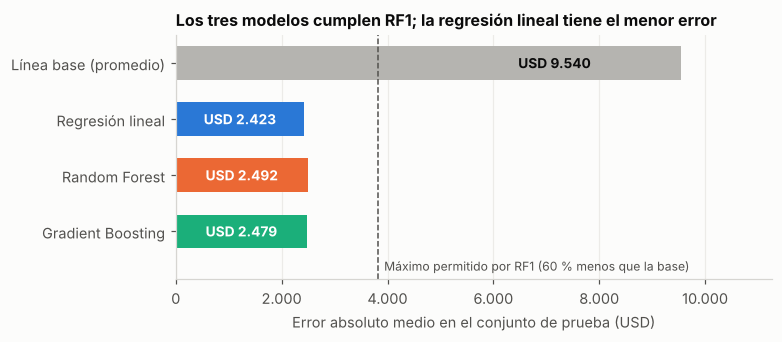

In [5]:
fig, ax = plt.subplots(figsize=(7.2, 3.2))
nombres = comparacion.index.tolist()
valores = comparacion["MAE (USD)"].values
colores = [GRIS, AZUL, NARANJA, AQUA]
barras = ax.barh(nombres[::-1], valores[::-1], color=colores[::-1], height=0.6)
etiquetas = [f"USD {v:,.0f}".replace(",", ".") for v in valores[::-1]]
for yv, (v, et) in enumerate(zip(valores[::-1], etiquetas)):
    es_base = yv == len(valores) - 1
    ax.text(v * (0.75 if es_base else 0.5), yv, et, ha="center", va="center", fontsize=9, fontweight="bold",
            color=TINTA if es_base else "white")
umbral = mae_base * 0.40
ax.axvline(umbral, color=TINTA2, lw=1, ls="--")
ax.text(umbral + 120, -0.62, "Máximo permitido por RF1 (60 % menos que la base)", fontsize=8, color=TINTA2, va="center")
ax.set_ylim(-0.85, 3.5)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", ".")))
ax.set_xlim(0, mae_base * 1.18)
ax.set_xlabel("Error absoluto medio en el conjunto de prueba (USD)")
ax.set_title("Los tres modelos cumplen RF1; la regresión lineal tiene el menor error", loc="left", fontsize=10.5)
ax.grid(axis="x", color="#ecebe8", lw=0.8); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig("figuras/fig_modelos.png", dpi=200); plt.show()

**Conclusión.** Los tres modelos cumplen RF1 con margen. Elegimos la **regresión lineal con la interacción
fumador × obeso**: tiene el menor error (MAE USD 2.423, 74,6 % menos que la línea base), el R² más alto (0,890)
y además es interpretable, porque cada coeficiente se puede explicar a Finanzas y a Legal (RNF4).
Con la interacción, la regresión lineal deja de quedar atrás de los modelos de árboles, como pasaba en el
informe de factibilidad.

## 4. Validación cruzada (T6 · H4)

Una sola partición 75/25 puede tener suerte. Con validación cruzada de 5 particiones comprobamos que el
resultado se sostiene con otros datos de prueba.

In [6]:
kf = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)
filas = []
for nombre, modelo in modelos.items():
    cv = cross_validate(modelo, X, y, cv=kf, scoring=["r2", "neg_mean_absolute_error"])
    filas.append([nombre, cv["test_r2"].mean(), cv["test_r2"].std(),
                  -cv["test_neg_mean_absolute_error"].mean(), cv["test_neg_mean_absolute_error"].std()])
validacion = pd.DataFrame(filas, columns=["Modelo", "R² medio", "R² desv.", "MAE medio (USD)", "MAE desv. (USD)"]).set_index("Modelo")
validacion.style.format({"R² medio": "{:.3f}", "R² desv.": "{:.3f}", "MAE medio (USD)": "{:,.0f}", "MAE desv. (USD)": "{:,.0f}"})

,R² medio,R² desv.,MAE medio (USD),MAE desv. (USD)
Modelo,,,,
Regresión lineal,0.859,0.030,"2,472",150
Random Forest,0.849,0.027,"2,532",102
Gradient Boosting,0.851,0.028,"2,545",86


**Conclusión.** En validación cruzada el R² baja a entre 0,85 y 0,86 en los tres modelos, pero sigue sobre 0,80 en
todos. El resultado no dependía de una partición favorable: **RF1 se confirma y el hito H4 queda aprobado.**

## 5. Auditoría de equidad (T7 · H5)

El criterio de **RF2** es que la diferencia de MAE entre los subgrupos de cada variable sea menor a 25 %.
La medimos igual que en el plan: (MAE mayor − MAE menor) / MAE menor, siempre sobre el conjunto de prueba.

In [7]:
VARIABLES = [("sex", "Sexo"), ("tramo_edad", "Tramo de edad"), ("region", "Región"),
             ("smoker", "Fumador"), ("tramo_imc", "Tramo de IMC")]

def auditar(pred, indices):
    # Devuelve la diferencia de MAE entre subgrupos para cada variable sensible.
    t = df.loc[indices].copy()
    t["pred"] = pred
    filas = []
    for col, nombre in VARIABLES:
        mae = t.groupby(col, observed=True).apply(lambda g: mean_absolute_error(g.charges, g.pred))
        brecha = (mae.max() - mae.min()) / mae.min()
        filas.append([nombre, mae.idxmin(), mae.min(), mae.idxmax(), mae.max(), brecha])
    return pd.DataFrame(filas, columns=["Variable", "Grupo con menor error", "MAE menor", "Grupo con mayor error", "MAE mayor", "Diferencia"]).set_index("Variable")

formato = {"MAE menor": "{:,.0f}", "MAE mayor": "{:,.0f}", "Diferencia": "{:.0%}"}
auditoria_inicial = auditar(predicciones["Regresión lineal"], X_te.index)
auditoria_inicial.style.format(formato).apply(
    lambda s: ["color:#c0392b;font-weight:bold" if v >= 0.25 else "" for v in s], subset=["Diferencia"])

,Grupo con menor error,MAE menor,Grupo con mayor error,MAE mayor,Diferencia
Variable,,,,,
Sexo,female,"2,296",male,"2,568",12%
Tramo de edad,18–34,"2,237",35–49,"2,615",17%
Región,southwest,"1,821",northeast,"2,980",64%
Fumador,no,"2,298",yes,"2,905",26%
Tramo de IMC,IMC < 30,"2,207",IMC ≥ 30,"2,602",18%


In [8]:
resumen_modelos = pd.DataFrame({n: auditar(p, X_te.index)["Diferencia"] for n, p in predicciones.items()})
resumen_modelos.style.format("{:.0%}").apply(lambda s: ["color:#c0392b;font-weight:bold" if v >= 0.25 else "" for v in s])

,Regresión lineal,Random Forest,Gradient Boosting
Variable,,,
Sexo,12%,13%,13%
Tramo de edad,17%,31%,50%
Región,64%,22%,32%
Fumador,26%,8%,15%
Tramo de IMC,18%,18%,21%


**Conclusión.** Ningún modelo aprueba H5 tal como está. La regresión lineal falla en **región (64 %)** y
**fumador (26 %)**; el Random Forest y el Gradient Boosting fallan en **tramo de edad** (31 % y 50 %), y el Gradient
Boosting además en región. Es el riesgo R2 de la matriz, materializado. Lo registramos en Trello el 4 de
noviembre y abrimos la tarea no planificada **T14**.

## 6. Acción correctiva: experimentos de T14 (H5)

Probamos dos ideas sobre los tres modelos:

* **Sacar la región.** En el informe de factibilidad ya habíamos visto que la región funciona como *proxy*
  socioeconómico (southeast concentra más fumadores y el gasto más alto). Si el modelo se apoya en ella, puede
  castigar un territorio en vez de un riesgo.
* **Transformar el costo con logaritmo**, porque el gasto es muy asimétrico.

In [9]:
X_sin_region = construir_X(df, con_region=False)
Xs_tr, Xs_te = X_sin_region.loc[X_tr.index], X_sin_region.loc[X_te.index]
log_lineal = lambda: TransformedTargetRegressor(LinearRegression(), func=np.log, inverse_func=np.exp)
experimentos = {
    "Lineal, con región": (LinearRegression(), X_tr, X_te),
    "Lineal, con región y log": (log_lineal(), X_tr, X_te),
    "Lineal, sin región": (LinearRegression(), Xs_tr, Xs_te),
    "Lineal, sin región y log": (log_lineal(), Xs_tr, Xs_te),
    "Random Forest, sin región": (RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=SEMILLA, n_jobs=-1), Xs_tr, Xs_te),
}
filas, pred_exp = [], {}
for nombre, (modelo, a, b) in experimentos.items():
    modelo.fit(a, y_tr); p = modelo.predict(b); pred_exp[nombre] = p
    brechas = auditar(p, b.index)["Diferencia"]
    filas.append([nombre, r2_score(y_te, p), mean_absolute_error(y_te, p), brechas.max(), brechas.idxmax(),
                  "Sí" if brechas.max() < 0.25 else "No"])
t14 = pd.DataFrame(filas, columns=["Experimento", "R²", "MAE (USD)", "Peor diferencia", "En la variable", "Aprueba H5"]).set_index("Experimento")
t14.style.format({"R²": "{:.3f}", "MAE (USD)": "{:,.0f}", "Peor diferencia": "{:.0%}"})

,R²,MAE (USD),Peor diferencia,En la variable,Aprueba H5
Experimento,,,,,
"Lineal, con región",0.890,"2,423",64%,Región,No
"Lineal, con región y log",0.646,"3,751",545%,Fumador,No
"Lineal, sin región",0.888,"2,411",24%,Región,Sí
"Lineal, sin región y log",0.623,"3,813",543%,Fumador,No
"Random Forest, sin región",0.880,"2,531",37%,Tramo de edad,No


In [10]:
auditoria_final = auditar(pred_exp["Lineal, sin región"], X_te.index)
auditoria_final.style.format(formato)

,Grupo con menor error,MAE menor,Grupo con mayor error,MAE mayor,Diferencia
Variable,,,,,
Sexo,female,"2,288",male,"2,553",12%
Tramo de edad,18–34,"2,210",35–49,"2,626",19%
Región,southwest,"2,190",northeast,"2,708",24%
Fumador,no,"2,302",yes,"2,833",23%
Tramo de IMC,IMC < 30,"2,205",IMC ≥ 30,"2,583",17%


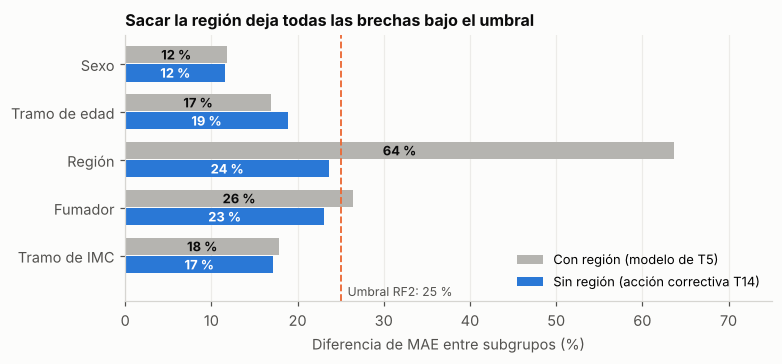

In [11]:
antes = auditoria_inicial["Diferencia"] * 100
despues = auditoria_final["Diferencia"] * 100
orden = antes.index.tolist()[::-1]
fig, ax = plt.subplots(figsize=(7.2, 3.4))
yy = np.arange(len(orden)); h = 0.36
b1 = ax.barh(yy + h/2 + 0.01, antes[orden], h, color=GRIS, label="Con región (modelo de T5)")
b2 = ax.barh(yy - h/2 - 0.01, despues[orden], h, color=AZUL, label="Sin región (acción correctiva T14)")
ax.bar_label(b1, labels=[f"{v:.0f} %" for v in b1.datavalues], label_type="center", fontsize=8.5, color=TINTA, fontweight="bold")
ax.bar_label(b2, labels=[f"{v:.0f} %" for v in b2.datavalues], label_type="center", fontsize=8.5, color="white", fontweight="bold")
ax.axvline(25, color=NARANJA, lw=1.2, ls="--")
ax.text(25.8, -0.75, "Umbral RF2: 25 %", color=TINTA2, fontsize=8, va="center")
ax.set_ylim(-0.95, len(orden) - 0.4)
ax.set_yticks(yy, orden); ax.set_xlim(0, 75)
ax.set_xlabel("Diferencia de MAE entre subgrupos (%)")
ax.set_title("Sacar la región deja todas las brechas bajo el umbral", loc="left", fontsize=10.5)
ax.legend(frameon=False, fontsize=8.5, loc="lower right")
ax.grid(axis="x", color="#ecebe8", lw=0.8); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig("figuras/fig_equidad.png", dpi=200); plt.show()

**Robustez.** La brecha de región sin esa variable queda en 24 %, muy cerca del límite. Para no aprobar H5 por
una partición favorable, repetimos la auditoría con las predicciones de la validación cruzada (cada afiliado es
predicho por un modelo que no lo vio al entrenar).

In [12]:
filas = []
for nombre, Xc in [("Con región", X), ("Sin región", X_sin_region)]:
    p = cross_val_predict(LinearRegression(), Xc, y, cv=kf)
    brechas = auditar(p, Xc.index)["Diferencia"]
    filas.append([nombre, r2_score(y, p), mean_absolute_error(y, p)] + brechas.tolist())
robustez = pd.DataFrame(filas, columns=["Modelo lineal", "R² (CV)", "MAE (CV)"] + [n for _, n in VARIABLES]).set_index("Modelo lineal")
robustez.style.format({"R² (CV)": "{:.3f}", "MAE (CV)": "{:,.0f}", **{n: "{:.0%}" for _, n in VARIABLES}})

,R² (CV),MAE (CV),Sexo,Tramo de edad,Región,Fumador,Tramo de IMC
Modelo lineal,,,,,,,
Con región,0.861,"2,472",12%,15%,46%,14%,10%
Sin región,0.860,"2,480",11%,14%,14%,14%,11%


**Conclusión de T14.**

* **Sacar la región funciona:** el R² apenas cambia (0,890 → 0,888) y el MAE incluso baja (USD 2.423 → 2.411).
  Con validación cruzada todas las brechas quedan en 14 % o menos, así que el resultado no es casualidad.
* **El logaritmo no sirve:** baja el R² a entre 0,62 y 0,65 y dispara las brechas, porque al volver a dólares
  subestima mucho a los fumadores.
* Modelo final: **regresión lineal sin sexo ni región, con la interacción fumador × obeso.** Con esto H5 vuelve
  a su fecha original. Igual que con el sexo en el informe de factibilidad, cumplir con la equidad no nos costó precisión.

In [13]:
modelo_final = LinearRegression().fit(Xs_tr, y_tr)
coef = pd.Series(modelo_final.coef_, index=Xs_tr.columns).round(0)
print(f"Intercepto: {modelo_final.intercept_:,.0f}")
coef.to_frame("Coeficiente (USD)")

Intercepto: -4,099


,Coeficiente (USD)
age,258.0
bmi,68.0
children,542.0
fumador,13278.0
obeso,-518.0
fumador_x_obeso,19642.0


Los coeficientes se leen directo: cada año de edad suma unos USD 258 al costo esperado, ser fumador suma
USD 13.278, y ser fumador **y** obeso suma USD 19.642 adicionales. Es la interacción que ya habíamos visto
en la exploración, ahora cuantificada dentro del modelo.

## 7. Puerta de calidad para el reentrenamiento (T11 · H6)

Este es el entregable funcional que se va a automatizar: una función que entrena el modelo y **sólo lo aprueba
si cumple RF1 y RF2 al mismo tiempo**. Si un reentrenamiento futuro empeora la equidad, la puerta lo rechaza
aunque el R² sea alto, y el modelo anterior sigue en uso.

In [14]:
def puerta_de_calidad(datos, umbral_r2=0.80, umbral_reduccion=0.60, umbral_brecha=0.25):
    # Entrena el modelo final y devuelve si puede pasar a producción.
    Xp = construir_X(datos, con_region=False)
    a_tr, a_te, b_tr, b_te = train_test_split(Xp, datos.charges, test_size=0.25, random_state=SEMILLA)
    modelo = LinearRegression().fit(a_tr, b_tr)
    pred = modelo.predict(a_te)
    r2 = r2_score(b_te, pred)
    reduccion = 1 - mean_absolute_error(b_te, pred) / mean_absolute_error(b_te, np.full(len(b_te), b_tr.mean()))
    brechas = auditar(pred, a_te.index)["Diferencia"]
    chequeos = {
        f"R² ≥ {umbral_r2}": bool(r2 >= umbral_r2),
        f"Reducción del MAE ≥ {umbral_reduccion:.0%}": bool(reduccion >= umbral_reduccion),
        f"Brecha máxima < {umbral_brecha:.0%}": bool(brechas.max() < umbral_brecha),
    }
    return {"aprobado": all(chequeos.values()), "R²": round(r2, 3), "reducción MAE": f"{reduccion:.1%}",
            "brecha máxima": f"{brechas.max():.0%} ({brechas.idxmax()})", "chequeos": chequeos, "modelo": modelo}

resultado = puerta_de_calidad(df)
{k: v for k, v in resultado.items() if k != "modelo"}

{'aprobado': True,
 'R²': 0.888,
 'reducción MAE': '74.7%',
 'brecha máxima': '24% (Región)',
 'chequeos': {'R² ≥ 0.8': True,
  'Reducción del MAE ≥ 60%': True,
  'Brecha máxima < 25%': True}}

**Conclusión.** El modelo final pasa la puerta de calidad. Esta misma función es la que T11 programa para
el reentrenamiento: si falla un chequeo, el despliegue se detiene y se avisa al equipo.

## 8. Salida para el dashboard (T10 · T13)

Por la restricción RR1 y el requerimiento RF3, el dashboard **nunca muestra predicciones por persona**: sólo
agregados por segmento para planificar el presupuesto. Generamos esa tabla y el dato del decil de mayor costo
que pidió Salud preventiva (T13).

In [15]:
df["costo_predicho"] = resultado["modelo"].predict(construir_X(df, con_region=False))
segmentos = (df.groupby(["tramo_edad", "smoker", "tramo_imc"], observed=True)
               .agg(afiliados=("charges", "size"), costo_predicho_medio=("costo_predicho", "mean"),
                    costo_predicho_total=("costo_predicho", "sum"))
               .reset_index().rename(columns={"smoker": "fumador"}))
segmentos["fumador"] = segmentos["fumador"].map({"yes": "Sí", "no": "No"})
segmentos = segmentos[segmentos.afiliados >= 10]       # no se publican segmentos con menos de 10 personas
segmentos.round(0).to_csv("salidas/segmentos_dashboard.csv", index=False)

umbral_decil = df.costo_predicho.quantile(0.90)
decil = df[df.costo_predicho >= umbral_decil]
print(f"Presupuesto anual predicho para la cartera: USD {df.costo_predicho.sum():,.0f}")
print(f"Decil de mayor costo predicho: {len(decil)} afiliados que concentran el "
      f"{decil.costo_predicho.sum() / df.costo_predicho.sum():.1%} del gasto predicho")
print(f"Segmentos publicados en el dashboard: {len(segmentos)} (archivo salidas/segmentos_dashboard.csv)")
segmentos.sort_values("costo_predicho_medio", ascending=False).head(6).style.format(
    {"costo_predicho_medio": "{:,.0f}", "costo_predicho_total": "{:,.0f}"})

Presupuesto anual predicho para la cartera: USD 17,761,578
Decil de mayor costo predicho: 134 afiliados que concentran el 31.6% del gasto predicho
Segmentos publicados en el dashboard: 12 (archivo salidas/segmentos_dashboard.csv)


,tramo_edad,fumador,tramo_imc,afiliados,costo_predicho_medio,costo_predicho_total
11,50–64,Sí,IMC ≥ 30,41,"46,097","1,889,993"
7,35–49,Sí,IMC ≥ 30,45,"42,313","1,904,065"
3,18–34,Sí,IMC ≥ 30,59,"37,470","2,210,708"
10,50–64,Sí,IMC < 30,27,"26,184","706,956"
6,35–49,Sí,IMC < 30,45,"22,611","1,017,509"
2,18–34,Sí,IMC < 30,57,"17,911","1,020,928"


## 9. Respaldo del monitoreo: plan vs. real

Esta sección no es técnica: genera la figura de la sección 1.2 del informe a partir de las fechas registradas
en Trello, para que el gráfico de plan vs. real también sea reproducible. Corte de control: martes 10 de noviembre.

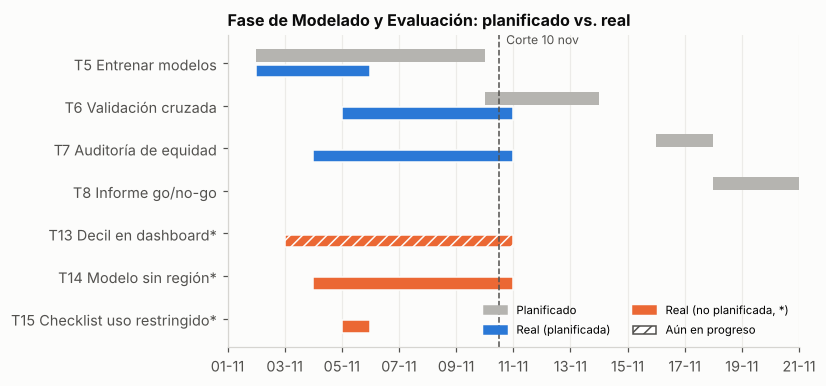

In [16]:
D = lambda s: pd.Timestamp(f"2026-{s}")
tareas = pd.DataFrame([
    # tarea, inicio plan, fin plan, inicio real, fin real (o corte si sigue en curso), estado
    ("T5 Entrenar modelos",         "11-02", "11-09", "11-02", "11-05", "Completada"),
    ("T6 Validación cruzada",       "11-10", "11-13", "11-05", "11-10", "Completada"),
    ("T7 Auditoría de equidad",     "11-16", "11-17", "11-04", "11-10", "Completada"),
    ("T8 Informe go/no-go",         "11-18", "11-20", None,    None,    "Pendiente"),
    ("T13 Decil en dashboard*",     None,    None,    "11-03", "11-10", "En progreso"),
    ("T14 Modelo sin región*",      None,    None,    "11-04", "11-10", "Completada"),
    ("T15 Checklist uso restringido*", None, None,    "11-05", "11-05", "Completada"),
], columns=["tarea", "ip", "fp", "ir", "fr", "estado"])

fig, ax = plt.subplots(figsize=(7.6, 3.6))
for i, r in enumerate(tareas.itertuples()):
    yv = len(tareas) - 1 - i
    if pd.notna(r.ip):
        ax.barh(yv + 0.18, (D(r.fp) - D(r.ip)).days + 1, left=D(r.ip), height=0.3, color=GRIS)
    if pd.notna(r.ir):
        color = NARANJA if r.tarea.endswith("*") else AZUL
        ax.barh(yv - 0.18, (D(r.fr) - D(r.ir)).days + 1, left=D(r.ir), height=0.3, color=color,
                hatch=None if r.estado == "Completada" else "///", edgecolor=FONDO)
ax.set_yticks(range(len(tareas)), tareas.tarea[::-1])
ax.axvline(D("11-10") + pd.Timedelta(hours=12), color=TINTA2, lw=1, ls="--")
ax.text(D("11-10") + pd.Timedelta(hours=18), len(tareas) - 0.55, "Corte 10 nov", fontsize=8, color=TINTA2)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=GRIS, label="Planificado"), Patch(color=AZUL, label="Real (planificada)"),
                   Patch(color=NARANJA, label="Real (no planificada, *)"),
                   Patch(facecolor="white", edgecolor=TINTA2, hatch="///", label="Aún en progreso")],
          frameon=False, fontsize=7.5, loc="lower right", ncol=2)
import matplotlib.dates as mdates
ax.xaxis.set_major_locator(mdates.DayLocator(interval=2)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%d-%m"))
ax.set_xlim(D("11-01"), D("11-21"))
ax.set_title("Fase de Modelado y Evaluación: planificado vs. real", loc="left", fontsize=10.5)
ax.grid(axis="x", color="#ecebe8", lw=0.8); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig("figuras/fig_gantt.png", dpi=200); plt.show()

## 10. Registro de avance técnico

Resumen de lo que dejó cada tarea, con las cifras que se citan en el informe.

In [17]:
lin = comparacion.loc["Regresión lineal"]
registro = pd.DataFrame([
    ["T3", "Calidad de datos", f"{df_original.shape[0]} registros, 0 nulos, 1 duplicado", "Completada"],
    ["T4", "Preparación", f"{len(df)} registros; sin sexo; 3 variables nuevas", "Completada"],
    ["T5", "Comparación de modelos", f"Lineal: R² {lin['R²']:.3f}, MAE USD {lin['MAE (USD)']:,.0f} ({lin['Reducción vs. base']:.1%} menos)", "Completada"],
    ["T6", "Validación cruzada", f"R² medio {validacion.loc['Regresión lineal', 'R² medio']:.3f} (5 particiones)", "Completada"],
    ["T7", "Auditoría de equidad", f"Inicial: región {auditoria_inicial.loc['Región', 'Diferencia']:.0%}, fumador {auditoria_inicial.loc['Fumador', 'Diferencia']:.0%}; final: máx. {auditoria_final['Diferencia'].max():.0%}", "Completada"],
    ["T14", "Acción correctiva", f"Sin región: R² {t14.loc['Lineal, sin región', 'R²']:.3f}, brecha máx. {t14.loc['Lineal, sin región', 'Peor diferencia']:.0%}", "Completada"],
    ["T11", "Puerta de calidad", "Aprobado" if resultado["aprobado"] else "Rechazado", "Prototipo listo"],
], columns=["Tarea", "Qué se hizo", "Resultado", "Estado al 10 nov"])
registro.style.hide(axis="index")

Tarea,Qué se hizo,Resultado,Estado al 10 nov
T3,Calidad de datos,"1338 registros, 0 nulos, 1 duplicado",Completada
T4,Preparación,1337 registros; sin sexo; 3 variables nuevas,Completada
T5,Comparación de modelos,"Lineal: R² 0.890, MAE USD 2,423 (74.6% menos)",Completada
T6,Validación cruzada,R² medio 0.859 (5 particiones),Completada
T7,Auditoría de equidad,"Inicial: región 64%, fumador 26%; final: máx. 24%",Completada
T14,Acción correctiva,"Sin región: R² 0.888, brecha máx. 24%",Completada
T11,Puerta de calidad,Aprobado,Prototipo listo


---
### Nota metodológica

Todas las métricas se calculan sobre datos que el modelo no vio al entrenar (25 % de prueba o validación cruzada).
Las cifras pueden diferir en algunos dólares de las del informe de factibilidad porque allí no habíamos eliminado
el duplicado ni excluido el sexo; por eso la línea base pasa de USD 9.253 a USD 9.540. Las dos advertencias de
siempre siguen vigentes: los datos son de EE. UU. sin mayores de 65 años, y la variable objetivo es el costo
facturado, no la necesidad de salud.